# Figure — **Cluster-level** intrinsic dimension across EMT states, 12 SCC tumours

**Dataset** [GSE288137](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE288137) — mouse
squamous cell carcinoma, 12 tumours, 23,959 cells across four EMT states.

> **The ID panel is a cluster-level estimate, not a per-cell one.** IDEAS was run with
> `method="2nn"` and `group=`, which returns **one ID per random subsample of a state**
> (2,886 cells, 100 subsamples per state) — not one ID per cell. Each point in
> that panel is a subsample, so the ID axis is on a different unit from everything else in
> this repository. A per-cell ID also exists for these 23,959 cells and is carried in
> the per-cell table as `ID_score_percell`; **it is not what the ID panel plots.**

Two inputs, because the two panels sit on different units:

| File | Rows |
|---|---|
| `Input_scc_12tumour_clusterID.csv` | 100 replicates × 4 states — the ID panel |
| `Input_scc_12tumour_percell.csv` | one row per barcode — the KS scatter |

Output: `figures/` (600 dpi PNG + vector PDF) and `source_data/`.
Provenance in `README.md`.


In [13]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, rankdata, norm, pearsonr
from statsmodels.stats.multitest import multipletests

FIG, SRC = "figures", "source_data"
os.makedirs(FIG, exist_ok=True); os.makedirs(SRC, exist_ok=True)

DPI = 600
mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": DPI, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.linewidth": 0.9, "axes.labelsize": 12, "axes.titlesize": 13,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
})
sns.set_theme(style="white", context="paper", rc=mpl.rcParams)

# Titles on or off. Journals want bare panels with the caption carrying the text.
SHOW_TITLES = True


def put_title(ax, text, fontsize=13):
    if SHOW_TITLES:
        ax.set_title(text, fontsize=fontsize)


def minmax(x):
    x = np.asarray(x, dtype=float)
    lo, hi = np.nanmin(x), np.nanmax(x)
    return (x - lo) / (hi - lo)


def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=DPI)
    fig.savefig(f"{FIG}/{name}.pdf")
    print(f"saved  {FIG}/{name}.png  +  .pdf")


def dunn(data, order):
    """Dunn's post-hoc: pooled ranks, tie correction, BH-FDR, rank-biserial."""
    allv = np.concatenate([data[g] for g in order])
    grp  = np.concatenate([np.repeat(g, len(data[g])) for g in order])
    ranks, N = rankdata(allv), len(allv)
    mean_rank = pd.DataFrame({"g": grp, "r": ranks}).groupby("g")["r"].mean()
    n = {g: len(data[g]) for g in order}
    _, tc = np.unique(allv, return_counts=True)
    tie = 1 - np.sum(tc ** 3 - tc) / (N ** 3 - N)

    def rb(x, y):
        r = rankdata(np.concatenate([x, y]))
        U = r[:len(x)].sum() - len(x) * (len(x) + 1) / 2
        return 2 * U / (len(x) * len(y)) - 1

    rows = []
    for a, b in combinations(order, 2):
        se = np.sqrt((N * (N + 1) / 12) * (1 / n[a] + 1 / n[b]) * tie)
        z = (mean_rank[a] - mean_rank[b]) / se
        rows.append({"group1": a, "group2": b, "z": z, "p": 2 * norm.sf(abs(z)),
                     "median_difference": np.median(data[a]) - np.median(data[b]),
                     "rank_biserial": rb(data[a], data[b])})
    out = pd.DataFrame(rows)
    out["q"] = multipletests(out["p"], method="fdr_bh")[1]
    out["signif"] = pd.cut(out["q"], [-np.inf, 1e-4, 1e-3, 1e-2, 5e-2, np.inf],
                           labels=["****", "***", "**", "*", "ns"])
    return out


---

## 1 · How the ID was calculated

**Cluster-level**, not per-cell. The four states differ in size from 3,608 to 9,985 cells, and
the 2NN estimate depends on sample size, so the states are compared at equal *n*: **2,886
cells** — 80 % of the smallest state — drawn at random, **100 times per state**.

**IDEAS** — <https://github.com/maddalenastn/IDEAS>, vendored in `../src/computeID/`.
Staiano M, Cirone N, Biondo M, Osella M, Scialdone A. *bioRxiv* 2025.
[doi:10.1101/2025.07.21.665922](https://doi.org/10.1101/2025.07.21.665922)

Verbatim from `../src/analysis_notebooks/local_id.ipynb`. The runnable version is
`../src/run_scripts/run_scc_cluster_ideas.py`, in the `ideas` environment (~15 min):

```python
import sys
sys.path.insert(0, "/home/csb/sampoorn/IDEAS")
from computeID.functions_IDEAS import compute_ID

# Smallest population = Hybrid = 3608; 80% of 3608 = 2886
# Therefore every state uses 2886 cells per replicate

id_reps = compute_ID(
    adata,
    group="celltype_annotation",
    method="2nn",
    sample_size=2886,
    n_samples=100,
    normalization=True,
    norm_sum=1e6,
    full_output=True,
    id_score=False
)
```



In [14]:
CLUSTER_ID = "Input_scc_12tumour_clusterID.csv"
ORDER = ["Epithelial", "Early-Hybrid", "Hybrid", "Late-EMT"]

id_reps = pd.read_csv(CLUSTER_ID, index_col=0)[ORDER]

print(f"{id_reps.shape[0]} replicates x {id_reps.shape[1]} states")
print("one ID per 2,886-cell subsample "
      "- NOT one per cell; see the note at the top")
display(id_reps.head())
display(id_reps.describe().round(4))


100 replicates x 4 states


,Epithelial,Early-Hybrid,Hybrid,Late-EMT
replicate,,,,
1,0.677742,0.611225,0.189814,0.032134
2,0.743790,0.699269,0.219388,0.105971
3,0.675973,0.896464,0.253398,0.189497
4,0.651595,0.706051,0.268698,0.209353
5,0.686535,0.642167,0.224658,0.221417


,Epithelial,Early-Hybrid,Hybrid,Late-EMT
count,100.0000,100.0000,100.0000,100.0000
mean,0.6798,0.6761,0.2460,0.1554
std,0.0800,0.0953,0.0524,0.0784
min,0.4367,0.4570,0.1028,0.0000
25%,0.6283,0.6157,0.2171,0.1022
50%,0.6778,0.6611,0.2514,0.1593
75%,0.7238,0.7316,0.2775,0.2221
max,0.9693,1.0000,0.3580,0.3134


---

## 2 · How the KS scores were calculated

ssGSEA enrichment scores for the mouse KS epithelial (164 genes) and KS mesenchymal
(48 genes) signatures, `gseapy.ssgsea` with `sample_norm_method="rank"`.




In [15]:
PERCELL = "Input_scc_12tumour_percell.csv"
cells = pd.read_csv(PERCELL, index_col=0)

print(f"{len(cells):,} cells x {cells.shape[1]} columns")
print(f"{cells['sample'].nunique()} tumours | assays: {dict(cells['assay'].value_counts())}")
print()
print(cells["cluster_annotation"].value_counts().reindex(ORDER).to_string())
display(cells.head(3))


23,959 cells x 15 columns
12 tumours | assays: {'scRNA': np.int64(14059), 'multiome': np.int64(9900)}

cluster_annotation
Epithelial      4146
Early-Hybrid    9985
Hybrid          3608
Late-EMT        6220


,cluster_annotation,sample,assay,ID_score_percell_raw,ID_score_percell,signalling_entropy_raw,signalling_entropy,transcriptome_entropy_raw,transcriptome_entropy,HPCS_ssGSEA_raw,HPCS_ssGSEA,KS_Epi_ssGSEA_raw,KS_Epi_ssGSEA,KS_Mes_ssGSEA_raw,KS_Mes_ssGSEA
barcode,,,,,,,,,,,,,,,
AAACCCACACGGCACT-1,Hybrid,SC2b3,scRNA,24.7988,0.410039,0.267582,0.760047,7.43183,0.805193,0.276973,0.363884,-1063.390,0.163587,5959.38,0.907594
AAACGAAAGCTAATGA-1,Late-EMT,SC2b3,scRNA,23.1761,0.339866,0.206865,0.534436,7.30228,0.768483,0.641285,0.660256,-353.717,0.261967,5523.05,0.847031
AAACGAAAGGCTAGCA-1,Late-EMT,SC2b3,scRNA,24.9604,0.417031,0.105364,0.157277,6.94818,0.668144,0.246986,0.339489,-494.485,0.242452,4849.93,0.753603


---

## 3 · Panel 1 — ID score across EMT states

Box plot of the 100 replicates per state, with every replicate drawn as a jittered point.
Jitter seed 42, so the panel is reproducible. Code from `../src/analysis_notebooks/local_id.ipynb` cell 5.


saved  figures/panel01_id_across_emt_states.png  +  .pdf


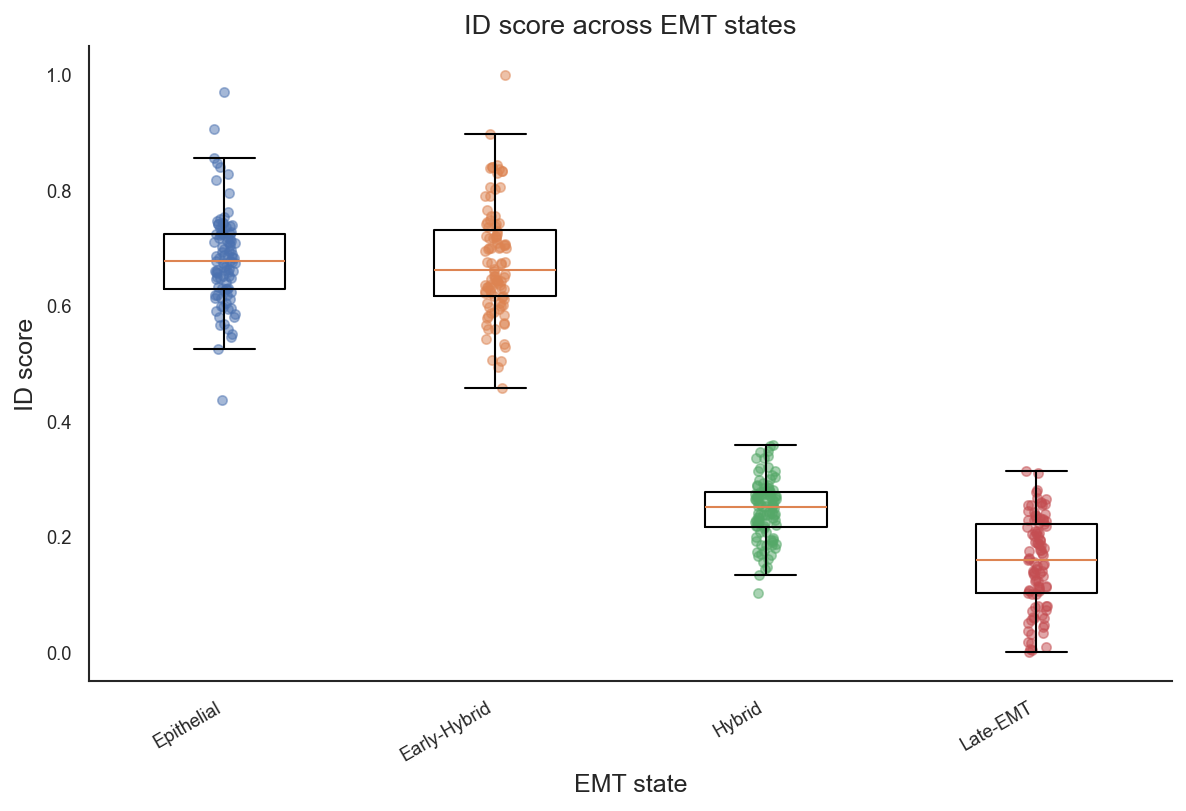

              count    mean  median     std
Epithelial    100.0  0.6798  0.6778  0.0800
Early-Hybrid  100.0  0.6761  0.6611  0.0953
Hybrid        100.0  0.2460  0.2514  0.0524
Late-EMT      100.0  0.1554  0.1593  0.0784


In [16]:
fig, ax = plt.subplots(figsize=(8, 5.5))

ax.boxplot([id_reps[s].dropna().values for s in ORDER],
           tick_labels=ORDER, showfliers=False)

rng = np.random.default_rng(42)
for i, state in enumerate(ORDER, start=1):
    v = id_reps[state].dropna().values
    ax.scatter(i + rng.uniform(-0.04, 0.04, len(v)), v, s=20, alpha=0.5)

ax.set_ylabel("Cluster-level ID score", fontsize=12)
ax.set_xlabel("EMT state", fontsize=12)
put_title(ax, "Cluster-level ID score across EMT states\n(2NN on 2,886-cell subsamples, 100 per state)", 12)
ax.set_xticks(range(1, len(ORDER) + 1))
ax.set_xticklabels(ORDER, rotation=30, ha="right")
sns.despine(ax=ax)
fig.tight_layout()
save(fig, "panel01_id_across_emt_states")
plt.show()

summary = id_reps[ORDER].agg(["count", "mean", "median", "std"]).T.round(4)
print(summary.to_string())
summary.to_csv(f"{SRC}/panel01_id_across_emt_states.csv")


---

## 4 · Statistics — Kruskal-Wallis and Dunn

The 100 replicates per state are resamples of the same 23,959 cells, so these p-values speak
to how stable the estimate is, not to how many independent tumours were measured. Raising
`n_samples` would lower every p-value.


Kruskal-Wallis:  H = 315.17   p = 5.179e-68

      group1       group2         z            p  median_difference  rank_biserial            q signif
  Epithelial Early-Hybrid  0.291126 7.709553e-01           0.016756         0.0476 7.709553e-01     ns
  Epithelial       Hybrid 10.388169 2.806906e-25           0.426368         1.0000 5.613811e-25   ****
  Epithelial     Late-EMT 14.367293 8.301305e-47           0.518472         1.0000 4.980783e-46   ****
Early-Hybrid       Hybrid 10.097043 5.693296e-24           0.409613         1.0000 8.539944e-24   ****
Early-Hybrid     Late-EMT 14.076167 5.321876e-45           0.501717         1.0000 1.596563e-44   ****
      Hybrid     Late-EMT  3.979124 6.916958e-05           0.092104         0.6506 8.300350e-05   ****
saved  figures/panel02_id_dunn.png  +  .pdf


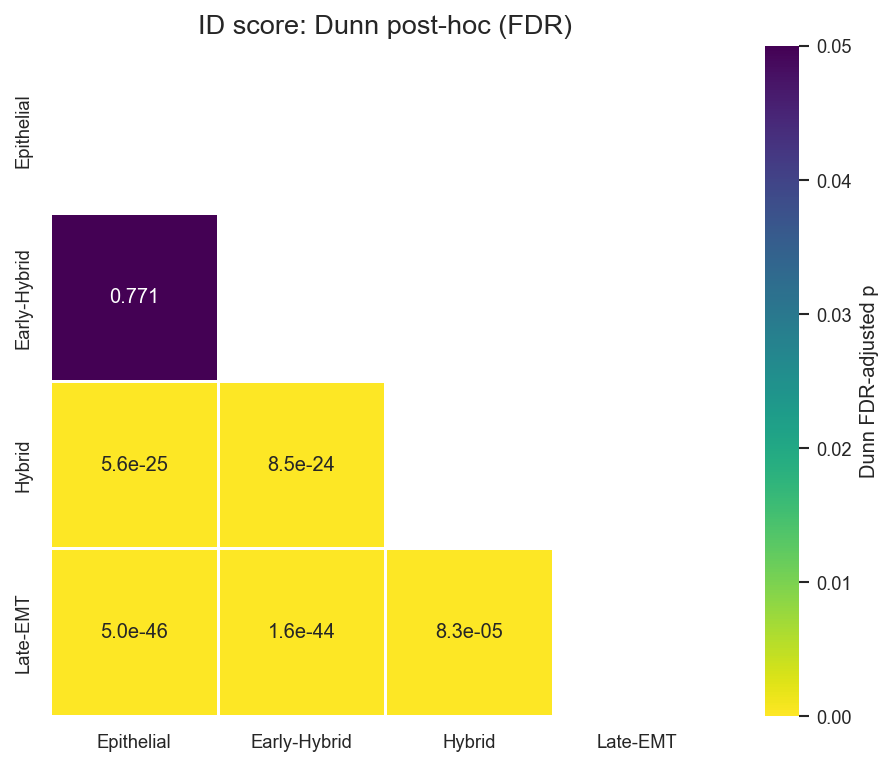

In [17]:
data = {s: id_reps[s].dropna().values for s in ORDER}
H, p_kw = kruskal(*[data[s] for s in ORDER])
print(f"Kruskal-Wallis:  H = {H:.2f}   p = {p_kw:.3e}\n")

tab = dunn(data, ORDER)
print(tab.to_string(index=False))
tab.to_csv(f"{SRC}/panel01_statistics.csv", index=False)

m = pd.DataFrame(np.nan, index=ORDER, columns=ORDER)
for _, r in tab.iterrows():
    m.loc[r["group2"], r["group1"]] = r["q"]
lab = m.map(lambda p: "" if pd.isna(p) else (f"{p:.1e}" if p < 1e-3 else f"{p:.3f}"))

fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(m.clip(upper=.05), mask=m.isna(), annot=lab, fmt="", cmap="viridis_r",
            vmin=0, vmax=.05, square=True, linewidths=.7, linecolor="white",
            cbar_kws={"label": "Dunn FDR-adjusted p"}, ax=ax)
put_title(ax, "Cluster-level ID score: Dunn post-hoc (FDR)")
fig.tight_layout()
save(fig, "panel02_id_dunn")
plt.show()


---

## 5 · Panel 3 — KS-Epi versus KS-Mes across EMT states

Each point is a cell, coloured by EMT state, with the overall linear trend dashed in black.
Code from `../src/analysis_notebooks/id_entropy_12_emt_scc.ipynb` cell 82.


Pearson r = -0.627   p = 0.000e+00   n = 23,959

cluster_annotation
Epithelial      4146
Early-Hybrid    9985
Hybrid          3608
Late-EMT        6220
saved  figures/panel03_ks_epi_vs_mes.png  +  .pdf


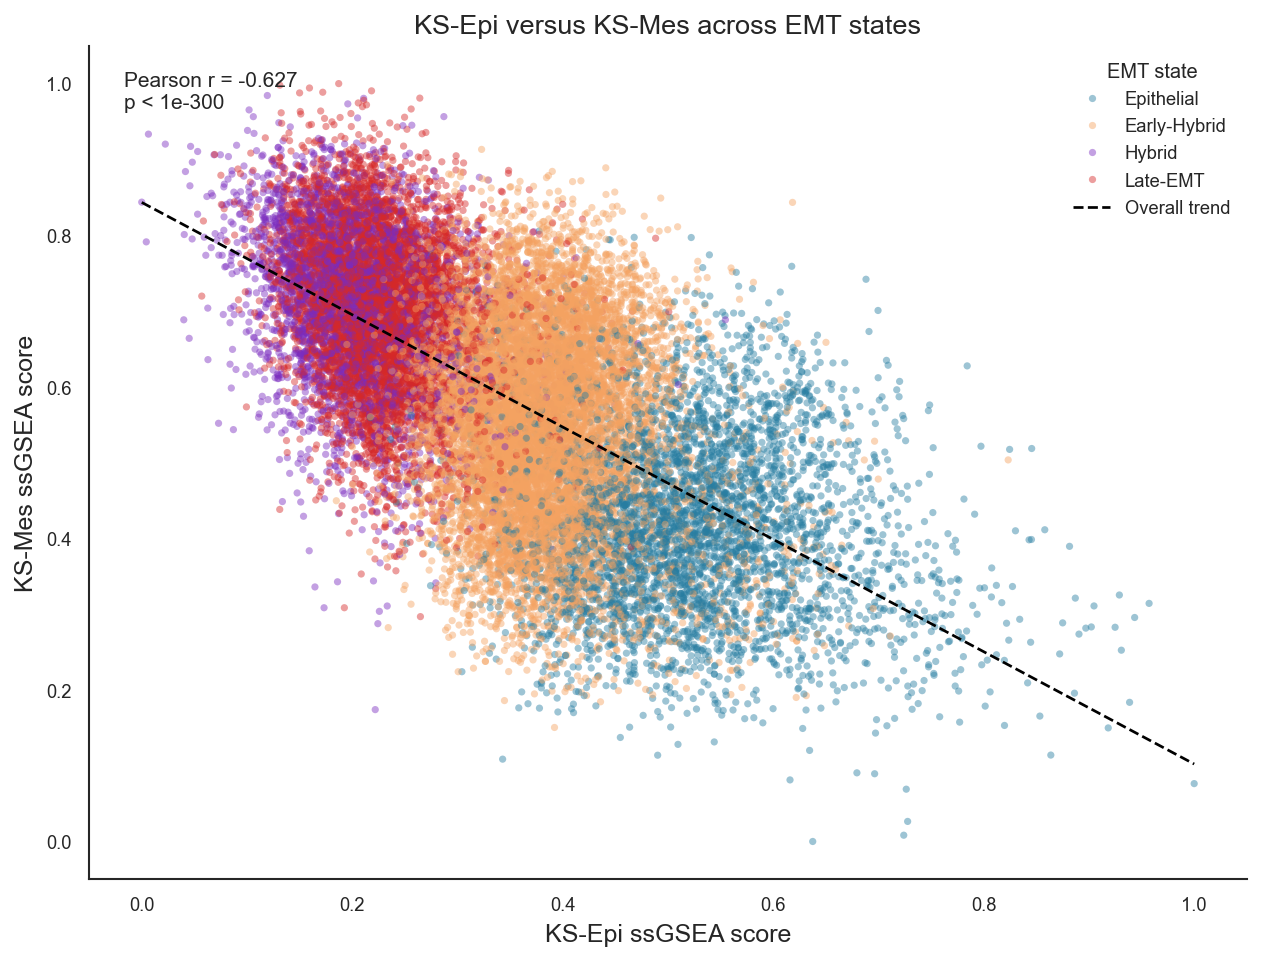

,emt_state,n,pearson_r,p
0,Epithelial,4146,-0.142718,2.605135e-20
1,Early-Hybrid,9985,-0.115716,4.099212e-31
2,Hybrid,3608,-0.301572,9.556819e-77
3,Late-EMT,6220,-0.246783,5.891209e-87
4,all,23959,-0.627103,0.000000e+00


In [18]:
KS_GROUP = "cluster_annotation"
KS_ORDER = ORDER                      # same four states as the ID panel

plot_df = (cells[[KS_GROUP, "KS_Epi_ssGSEA", "KS_Mes_ssGSEA"]]
           .replace([np.inf, -np.inf], np.nan).dropna()
           .loc[lambda x: x[KS_GROUP].isin(KS_ORDER)].copy())

r, p = pearsonr(plot_df["KS_Epi_ssGSEA"], plot_df["KS_Mes_ssGSEA"])
print(f"Pearson r = {r:.3f}   p = {p:.3e}   n = {len(plot_df):,}\n")
print(plot_df[KS_GROUP].value_counts().reindex(KS_ORDER).to_string())

palette = {"Epithelial": "#277DA1", "Early-Hybrid": "#F4A261",
           "Hybrid": "#7B2CBF", "Late-EMT": "#D62828"}

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.scatterplot(data=plot_df, x="KS_Epi_ssGSEA", y="KS_Mes_ssGSEA",
                hue=KS_GROUP, hue_order=KS_ORDER, palette=palette,
                s=12, alpha=0.45, linewidth=0, rasterized=True, ax=ax)

x = plot_df["KS_Epi_ssGSEA"].to_numpy()
slope, intercept = np.polyfit(x, plot_df["KS_Mes_ssGSEA"].to_numpy(), 1)
x_line = np.linspace(0, 1, 200)
ax.plot(x_line, slope * x_line + intercept, color="black", linestyle="--",
        linewidth=1.3, label="Overall trend")

ax.set_xlabel("KS-Epi ssGSEA score", fontsize=12)
ax.set_ylabel("KS-Mes ssGSEA score", fontsize=12)
put_title(ax, "KS-Epi versus KS-Mes across EMT states")
p_text = "p < 1e-300" if p == 0 else f"p = {p:.2e}"
ax.text(0.03, 0.97, f"Pearson r = {r:.3f}\n{p_text}", transform=ax.transAxes,
        ha="left", va="top", fontsize=10)
ax.legend(title="EMT state", frameon=False, loc="best")
sns.despine(ax=ax)
fig.tight_layout()
save(fig, "panel03_ks_epi_vs_mes")
plt.show()

rows = []
for g in KS_ORDER:
    s = plot_df[plot_df[KS_GROUP] == g]
    rg, pg = pearsonr(s["KS_Epi_ssGSEA"], s["KS_Mes_ssGSEA"])
    rows.append({"emt_state": g, "n": len(s), "pearson_r": rg, "p": pg})
rows.append({"emt_state": "all", "n": len(plot_df), "pearson_r": r, "p": p})
ks_stats = pd.DataFrame(rows)
ks_stats.to_csv(f"{SRC}/panel03_statistics.csv", index=False)
display(ks_stats)


---

## 6 · Panel 4 — the HPCS programme across the EMT states

The HPCS signature was defined in the KP lung tumours (`../Figure_hpcs/`). Here the same
23,959 SCC cells are scored for it by ssGSEA (`HPCS_ssGSEA`) and compared across the four EMT
states — does a programme defined in a different tumour type track EMT here too?


Kruskal-Wallis: H = 1308.36, p = 2.257e-283
                       n  median
cluster_annotation              
Epithelial          4146  0.5110
Early-Hybrid        9985  0.5548
Hybrid              3608  0.4977
Late-EMT            6220  0.4764
saved  figures/panel04_hpcs_programme.png  +  .pdf


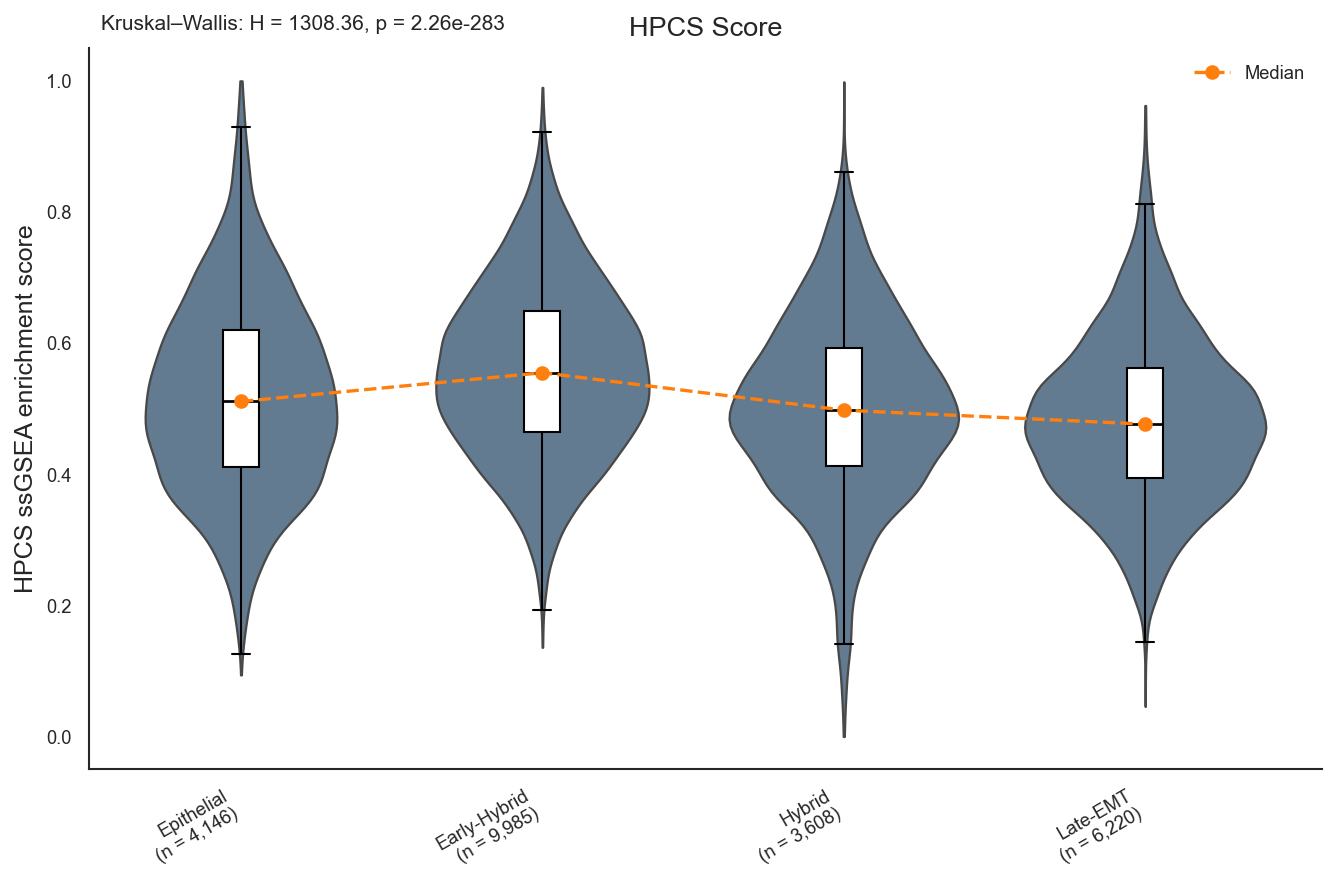

In [21]:
SCC_ORDER = ORDER                     # same four states as the ID panel

prog = cells[["cluster_annotation", "HPCS_ssGSEA"]].dropna()
prog = prog[prog["cluster_annotation"].isin(SCC_ORDER)]

groups = [prog.loc[prog["cluster_annotation"] == g, "HPCS_ssGSEA"].values for g in SCC_ORDER]
H_scc, p_scc = kruskal(*groups)

counts  = prog.groupby("cluster_annotation", observed=True).size().reindex(SCC_ORDER)
medians = prog.groupby("cluster_annotation", observed=True)["HPCS_ssGSEA"].median().reindex(SCC_ORDER)

print(f"Kruskal-Wallis: H = {H_scc:.2f}, p = {p_scc:.3e}")
print(pd.DataFrame({"n": counts, "median": medians.round(4)}).to_string())

fig, ax = plt.subplots(figsize=(9, 6))
sns.violinplot(data=prog, x="cluster_annotation", y="HPCS_ssGSEA", order=SCC_ORDER,
               inner=None, cut=0, linewidth=1.1, color="#5B7C99", ax=ax)
sns.boxplot(data=prog, x="cluster_annotation", y="HPCS_ssGSEA", order=SCC_ORDER,
            width=0.12, showfliers=False,
            boxprops=dict(facecolor="white", edgecolor="black", linewidth=1.0),
            whiskerprops=dict(color="black", linewidth=1.0),
            capprops=dict(color="black", linewidth=1.0),
            medianprops=dict(color="black", linewidth=1.3), ax=ax)
ax.plot(np.arange(len(SCC_ORDER)), medians.values, color="#ff7f0e", linestyle="--",
        linewidth=1.6, marker="o", markersize=6, label="Median", zorder=5)

p_txt = "p < 1e-300" if p_scc == 0 else f"p = {p_scc:.2e}"
ax.text(0.01, 1.02, f"Kruskal–Wallis: H = {H_scc:.2f}, {p_txt}",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=10)
ax.set_xticks(range(len(SCC_ORDER)))
ax.set_xticklabels([f"{g}\n(n = {counts[g]:,})" for g in SCC_ORDER],
                   rotation=30, ha="right", fontsize=9)
ax.set_xlabel("")
ax.set_ylabel("HPCS ssGSEA enrichment score", fontsize=12)
put_title(ax, "HPCS Score")
ax.legend(frameon=False, loc="upper right")
sns.despine(ax=ax)
fig.tight_layout()
save(fig, "panel04_hpcs_programme")
plt.show()


---

## 7 · Panel 5 — HPCS programme, pairwise Dunn


      group1       group2          z             p  median_difference  rank_biserial             q signif
  Epithelial Early-Hybrid -15.999557  1.286868e-57          -0.043816      -0.164543  2.573737e-57   ****
  Epithelial       Hybrid   4.383419  1.168310e-05           0.013278       0.054727  1.168310e-05   ****
  Epithelial     Late-EMT  13.221072  6.631212e-40           0.034560       0.144887  9.946818e-40   ****
Early-Hybrid       Hybrid  20.355728  4.130710e-92           0.057094       0.229504  1.239213e-91   ****
Early-Hybrid     Late-EMT  34.709918 5.582357e-264           0.078376       0.327090 3.349414e-263   ****
      Hybrid     Late-EMT   7.897587  2.843545e-15           0.021282       0.095442  3.412253e-15   ****
saved  figures/panel05_hpcs_programme_dunn.png  +  .pdf


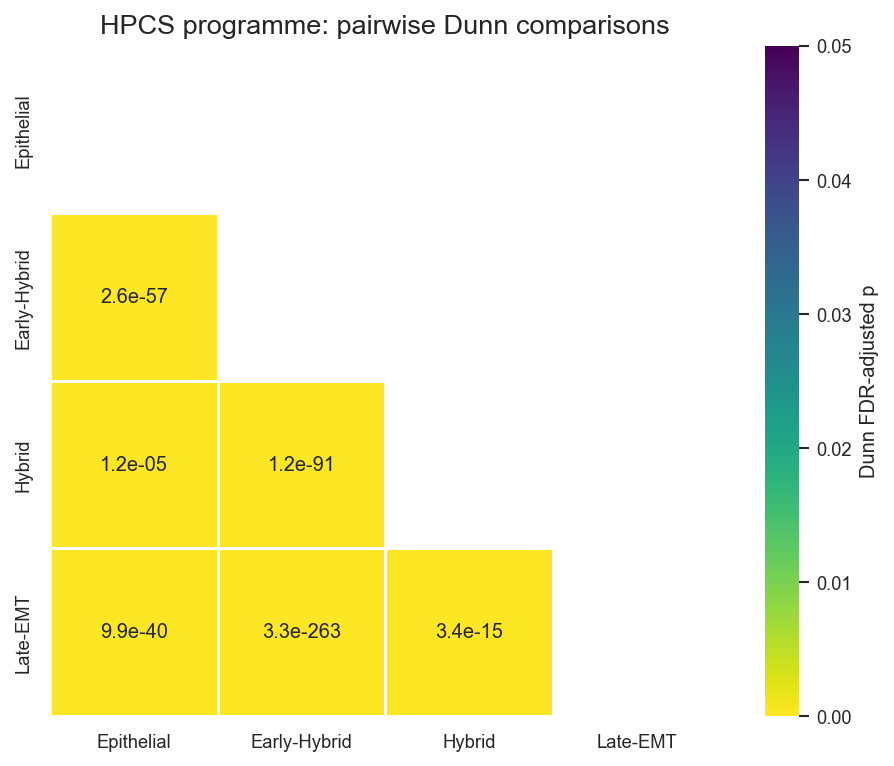

In [20]:
pdata = {g: prog.loc[prog["cluster_annotation"] == g, "HPCS_ssGSEA"].values
         for g in SCC_ORDER}
ptab = dunn(pdata, SCC_ORDER)
print(ptab.to_string(index=False))
ptab.to_csv(f"{SRC}/panel05_hpcs_programme_statistics.csv", index=False)

m = pd.DataFrame(np.nan, index=SCC_ORDER, columns=SCC_ORDER)
for _, r in ptab.iterrows():
    m.loc[r["group2"], r["group1"]] = r["q"]
lab = m.map(lambda p: "" if pd.isna(p) else (f"{p:.1e}" if p < 1e-3 else f"{p:.3f}"))

fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(m.clip(upper=.05), mask=m.isna(), annot=lab, fmt="", cmap="viridis_r",
            vmin=0, vmax=.05, square=True, linewidths=.7, linecolor="white",
            cbar_kws={"label": "Dunn FDR-adjusted p"}, ax=ax)
put_title(ax, "HPCS programme: pairwise Dunn comparisons")
fig.tight_layout()
save(fig, "panel05_hpcs_programme_dunn")
plt.show()


---

## 8 · Source data

| File | Contents |
|---|---|
| `panel01_id_across_emt_states.csv` | ID: count, mean, median, sd per state |
| `panel01_statistics.csv` | Kruskal-Wallis + Dunn table |
| `panel03_statistics.csv` | KS: Pearson r per state and overall |
| `panel05_hpcs_programme_statistics.csv` | HPCS programme Dunn table |
